**Load and understand behavior**

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", palette="Set2")

df = pd.read_csv("customer_data.csv", parse_dates=["last_purchase_date"])
df.head()

,customer_id,name,age,gender,city,favorite_category,total_orders,total_spent,last_purchase_date
0,C2000,Anjali Roy,34,Female,Delhi,Sports,12,4500.0,2026-01-31
1,C2001,Anjali Mehta,48,Female,Pune,Sports,7,8552.0,2026-05-20
2,C2002,Meera Mehta,46,Male,Mumbai,Groceries,5,8743.0,2026-04-25
3,C2003,Aditya Joshi,29,Male,Bangalore,Beauty,10,18501.0,2025-12-11
4,C2004,Arjun Nair,31,Female,Delhi,Sports,5,8306.0,2025-11-04


In [3]:
df[["age", "total_orders", "total_spent"]].describe()

,age,total_orders,total_spent
count,200.000000,200.00000,200.00000
mean,34.260000,7.13000,12044.62500
std,9.037187,2.47055,7213.21061
min,18.000000,2.00000,1254.00000
25%,28.000000,5.00000,6748.75000
50%,34.000000,7.00000,10029.50000
75%,40.000000,9.00000,15412.75000
max,60.000000,14.00000,43182.00000


In [4]:
df["avg_order_value"] = (df["total_spent"] / df["total_orders"]).round(0)
df["days_since_purchase"] = (pd.Timestamp("2026-10-24") - df["last_purchase_date"]).dt.days

**Segment customers**

In [6]:
# By age
df["age_group"] = pd.cut(df["age"], [17,25,35,45,60], labels=["18-25","26-35","36-45","46-60"])
print(df.groupby("age_group", observed=True)["total_spent"].agg(["count","mean","sum"]).round(0))

           count     mean        sum
age_group                           
18-25         30  10185.0   305553.0
26-35         78  13320.0  1038996.0
36-45         70  12002.0   840156.0
46-60         22  10192.0   224220.0


In [7]:
# By location
print(df.groupby("city")["total_spent"].agg(["count","mean","sum"]).round(0).sort_values("sum", ascending=False))

           count     mean       sum
city                               
Delhi         51  13836.0  705644.0
Mumbai        50  12350.0  617493.0
Bangalore     34  12725.0  432657.0
Hyderabad     26   9600.0  249606.0
Chennai       20  11736.0  234723.0
Pune          19   8884.0  168802.0


In [8]:
# By buying pattern (spend level)
df["segment"] = pd.qcut(df["total_spent"], 4, labels=["Bronze","Silver","Gold","Platinum"])
print(df.groupby("segment", observed=True)["total_spent"].agg(["count","sum"]))

          count        sum
segment                   
Bronze       50   246260.0
Silver       50   422081.0
Gold         50   632282.0
Platinum     50  1108302.0


**Most valuable customers**

In [9]:
top20 = df.nlargest(int(len(df)*0.2), "total_spent")
print("Top 20% customers contribute:", round(top20["total_spent"].sum()/df["total_spent"].sum()*100), "% of revenue")
top20[["customer_id","name","city","total_spent"]].head(10)

Top 20% customers contribute: 39 % of revenue


,customer_id,name,city,total_spent
147,C2147,Neha Patel,Chennai,43182.0
63,C2063,Imran Khan,Bangalore,40647.0
31,C2031,Nikhil Joshi,Mumbai,36303.0
99,C2099,Meera Khan,Mumbai,31710.0
111,C2111,Rahul Sharma,Pune,31320.0
145,C2145,Nikhil Reddy,Mumbai,28268.0
69,C2069,Arjun Iyer,Delhi,26496.0
175,C2175,Arjun Joshi,Delhi,26291.0
82,C2082,Sneha Sharma,Delhi,25948.0
20,C2020,Meera Singh,Mumbai,25562.0


In [11]:
print(df.groupby("favorite_category")["total_spent"].agg(["count","mean","sum"]).round(0))

                   count     mean       sum
favorite_category                          
Beauty                21  10615.0  222918.0
Electronics           47  18536.0  871198.0
Fashion               43  10091.0  433899.0
Groceries             41   9170.0  375957.0
Home & Kitchen        25  11215.0  280385.0
Sports                23   9764.0  224568.0


**Visual report**

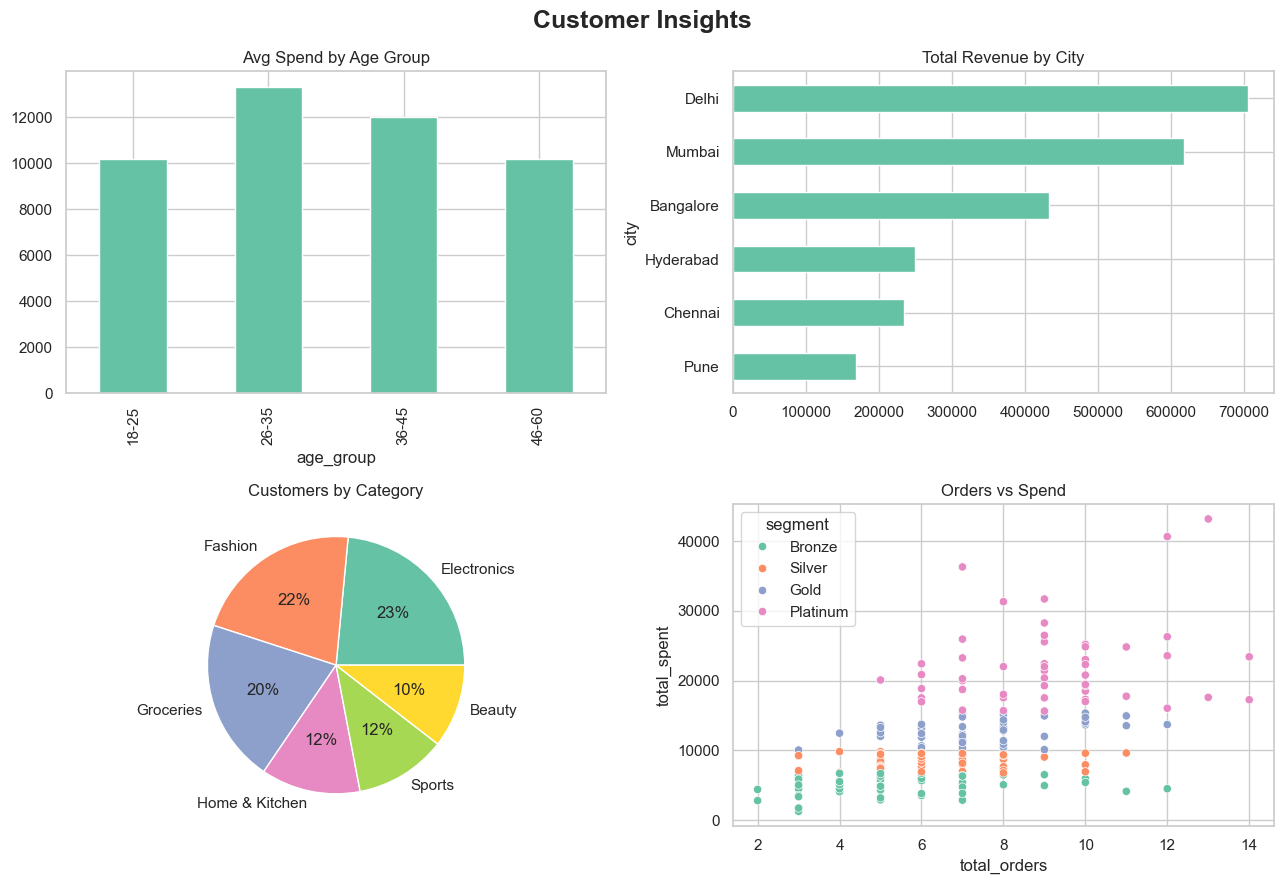

In [12]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle("Customer Insights", fontsize=18, fontweight="bold")

df.groupby("age_group", observed=True)["total_spent"].mean().plot(kind="bar", ax=ax[0,0], title="Avg Spend by Age Group")
df.groupby("city")["total_spent"].sum().sort_values().plot(kind="barh", ax=ax[0,1], title="Total Revenue by City")
df["favorite_category"].value_counts().plot(kind="pie", autopct="%1.0f%%", ax=ax[1,0], title="Customers by Category")
ax[1,0].set_ylabel("")
sns.scatterplot(data=df, x="total_orders", y="total_spent", hue="segment", ax=ax[1,1])
ax[1,1].set_title("Orders vs Spend")

plt.tight_layout()
plt.savefig("customer_dashboard.png", dpi=150)
plt.show()

**Insights from charts**

**1.Avg spend by age group:** 26-35 spend the most (about 13,300 per customer), followed by 36-45 (about 12,000). The 18-25 and 46-60 groups are lowest (about 10,200).

**2.Revenue by city:** Delhi leads with about 706K (29% of the total revenue of 2.41M), then Mumbai (617K) and Bangalore (433K). Pune is the lowest (169K), and its average spend is also the lowest.

**3.Customers by category:** Electronics (23%) and Fashion (22%) are the biggest groups. Electronics customers spend about 18,500 each, nearly double any other category.

**4.Orders vs spend:** more orders means more spend (correlation about 0.56), and Platinum customers sit at the top right.

**5.Most valuable customers:** the top 20% of customers bring in 39% of revenue. Platinum customers alone bring in 46% (1.1M of 2.4M). Most of them live in Delhi, and Electronics is their favorite category.

**6.Inactive customers:** 117 of 200 customers have not purchased in 180+ days, and they account for 58% of revenue. That is a big risk if they leave.


**Marketing strategies**

**Platinum customers:** loyalty rewards and early access to sales.

**Top age group and cities:** focus ad spend there.

**Electronics buyers:** cross-sell accessories, since they spend the most.

**Inactive customers (180+ days):** send a win-back discount.

**Low-spend cities:** run local offers.
